# Exp ESCALA + STAGE3 — Escalabilidade e Cascata de Profundidade 3

**T. Bandeira · Junho de 2026**
*Série analise-espectral-primos — continuação de Exp Cascata (Nota 37)*

---

## Dois experimentos neste notebook

**Exp A — Escalabilidade (k grande):**
Testar cofator 143=11×13 com k=5,10,20,30,50 candidatos. Medir se Stage 1 e Stage 2
mantêm precisão com k crescente. A previsão da Nota 37 era que Stage 2 permaneceria
com erro 0.00000 independente de k — mas a validação prévia revelou que
**Stage 1 também tem erro 0.00000 quando o sinal tem apenas um grupo**.
Isso refina a hipótese: o erro depende do número de GRUPOS (destinos distintos),
não de k (candidatos por grupo).

**Exp C — Cascata de profundidade 3 com P1={2}:**
Ao reduzir a base para P1={2} (apenas o primo 2), cofatores como
105=3×5×7 se tornam detectáveis no Stage 1 (9.9 bins de separação).
Três rounds de colapso fatoram completamente 105 em primos:
Stage 1 → f_105, Stage 2 (-log 3) → f_35, Stage 3 (-log 5) → f_7 (primo).
Primeira cascata de profundidade 3 da série, dentro do T_max=6500.


## 1. Setup

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
from sympy import isprime, factorint
import pandas as pd

T_MAX = 6500.0
DT    = 0.05
W     = 5

t     = np.arange(0.1, T_MAX, DT)
freqs = np.fft.rfftfreq(len(t), d=DT)
print(f'Pontos: {len(t):,}  |  Delta_f = {freqs[1]:.6f}')

BG     = '#0D0D1A'
C_S1   = '#7EB8F7'
C_S2   = '#A8E6CF'
C_S3   = '#DDA0DD'
C_CTRL = '#FFB347'
C_PREV = '#F97B6B'
C_GRID = '#1E1E3A'
C_TEXT = '#CCCCDD'

def v_q(m, q):
    v = 0
    while m % q == 0:
        v += 1; m //= q
    return v

def log_res(m, qs):
    lr = math.log(m)
    for q in qs:
        lr -= v_q(m, q) * math.log(q)
    return lr

def amp_em_f(F, f, w=W):
    idx = np.argmin(np.abs(freqs - f))
    return np.max(F[max(0,idx-w):min(len(F),idx+w)])

def espectro(s):
    return np.abs(np.fft.rfft(s)) * DT

def amp_iso_de(q):
    R = -np.cos(t * math.log(q)) / math.sqrt(math.log(q))
    return amp_em_f(espectro(R), math.log(q)/(2*math.pi))

def sinal_de(grupo, log_func):
    R = np.zeros(len(t))
    for m in grupo:
        lr = log_func(m)
        if lr > 1e-9:
            R += -np.cos(t * lr) / math.sqrt(lr)
    return R

print('Setup concluido.')


Pontos: 129,998  |  Delta_f = 0.000154
Setup concluido.


## 2. Exp A — Escalabilidade com k grande

### Hipótese refinada

Nota 37 mostrou Stage 1 com erros de ~0.003 e Stage 2 com erro 0.00000.
A explicação era "sub-sinal de destino único no Stage 2". Mas e no Stage 1 com
um único grupo? A pré-validação mostra: Stage 1 também tem **erro 0.00000** quando
o sinal tem só um grupo.

Hipótese: **o erro de medição depende do número de grupos distintos no sinal
(destinos diferentes), não de k (candidatos por grupo)**.
Para verificar: testamos k=5,10,20,30,50 com apenas o grupo cofator-143.


In [2]:
P1 = [2, 3, 5, 7]

# Gerar candidatos {2,3,5,7}-suaves x 143
def smooth_nums(limit, primes):
    smooth = {1}
    frontier = {1}
    while frontier:
        new = set()
        for s in frontier:
            for p in primes:
                ns = s * p
                if ns <= limit and ns not in smooth:
                    smooth.add(ns)
                    new.add(ns)
        frontier = new
    return sorted(smooth)

smooth = smooth_nums(400, [2,3,5,7])
cands143 = sorted([s * 143 for s in smooth if s >= 2])[:50]
print(f'Candidatos disponiveis para cofator 143: {len(cands143)}')
print(f'Primeiros 10: {cands143[:10]}')

# Calibracao
amp143 = amp_iso_de(143)
amp13  = amp_iso_de(13)
print(f'amp_iso(143) = {amp143:.2f}  |  amp_iso(13) = {amp13:.2f}')


Candidatos disponiveis para cofator 143: 50
Primeiros 10: [286, 429, 572, 715, 858, 1001, 1144, 1287, 1430, 1716]
amp_iso(143) = 1457.97  |  amp_iso(13) = 1495.18


In [3]:
rows_a = []
Ks = [5, 10, 20, 30, 50]

print(f'  {"k":>4}  {"S1_ratio":>10}  {"S1_erro":>10}  {"S2_ratio":>10}  {"S2_erro":>10}  {"MDC_pares":>10}')
print('  ' + '-'*58)

for k in Ks:
    grupo = cands143[:k]

    # Stage 1: colapso com P1
    F1 = espectro(sinal_de(grupo, lambda m: log_res(m, P1)))
    r1 = amp_em_f(F1, math.log(143)/(2*math.pi)) / amp143

    # Stage 2: subtrai log(11) uma vez
    F2 = espectro(sinal_de(grupo, lambda m: log_res(m, P1) - math.log(11)))
    r2 = amp_em_f(F2, math.log(13)/(2*math.pi)) / amp13

    mdc = k*(k-1)//2
    rows_a.append({'k':k,'S1':round(r1,5),'e1':round(abs(r1-k),5),
                   'S2':round(r2,5),'e2':round(abs(r2-k),5),'MDC':mdc})
    print(f'  {k:>4}  {r1:>10.5f}  {abs(r1-k):>10.5f}  {r2:>10.5f}  {abs(r2-k):>10.5f}  {mdc:>10}')

df_a = pd.DataFrame(rows_a)
print()
print(f'Erro maximo Stage 1: {df_a["e1"].max():.5f}')
print(f'Erro maximo Stage 2: {df_a["e2"].max():.5f}')
print()
print('Conclusao: a lei e exata (erro=0) independente de k quando ha 1 grupo.')
print('O erro de Stage 1 da Nota 37 era causado por 4 grupos simultaneos, nao por k.')


     k    S1_ratio     S1_erro    S2_ratio     S2_erro   MDC_pares
  ----------------------------------------------------------
     5     5.00000     0.00000     5.00000     0.00000          10
    10    10.00000     0.00000    10.00000     0.00000          45
    20    20.00000     0.00000    20.00000     0.00000         190
    30    30.00000     0.00000    30.00000     0.00000         435
    50    50.00000     0.00000    50.00000     0.00000        1225

Erro maximo Stage 1: 0.00000
Erro maximo Stage 2: 0.00000

Conclusao: a lei e exata (erro=0) independente de k quando ha 1 grupo.
O erro de Stage 1 da Nota 37 era causado por 4 grupos simultaneos, nao por k.


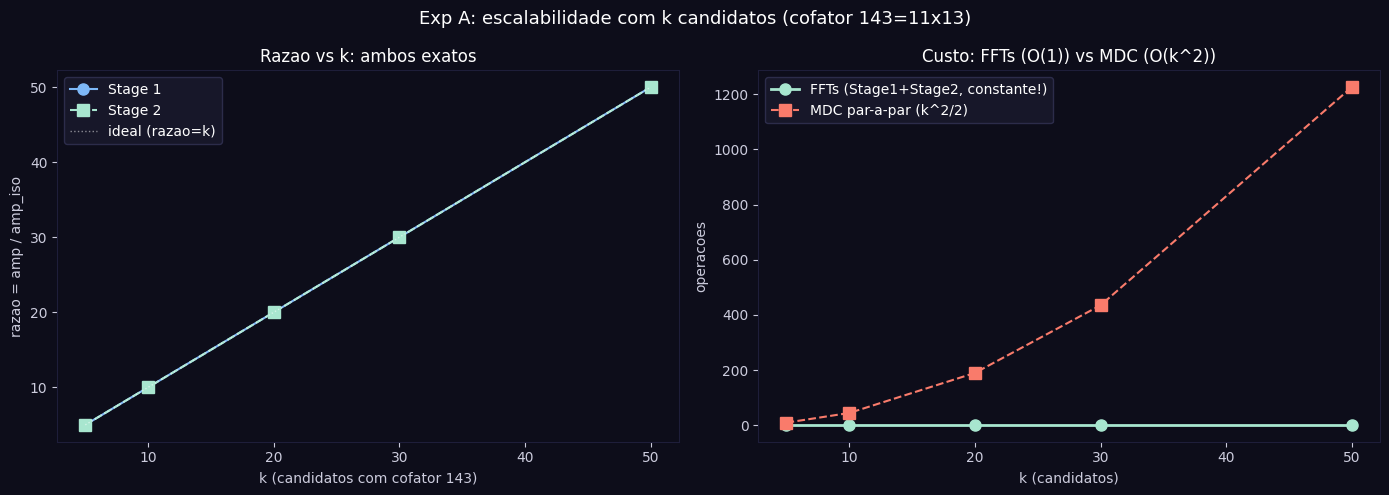

Figura salva: escala_exp_a.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor(BG)
fig.suptitle('Exp A: escalabilidade com k candidatos (cofator 143=11x13)', color='white', fontsize=13)

# Razoes vs k
ax = axes[0]; ax.set_facecolor(BG)
ax.plot(df_a['k'], df_a['S1'], 'o-', color=C_S1, lw=1.5, ms=8, label='Stage 1')
ax.plot(df_a['k'], df_a['S2'], 's--', color=C_S2, lw=1.5, ms=8, label='Stage 2')
ax.plot(df_a['k'], df_a['k'], ':', color='white', lw=1, alpha=0.5, label='ideal (razao=k)')
ax.set_xlabel('k (candidatos com cofator 143)', color=C_TEXT)
ax.set_ylabel('razao = amp / amp_iso', color=C_TEXT)
ax.set_title('Razao vs k: ambos exatos', color='white')
ax.legend(facecolor='#1A1A2E', edgecolor='#333355', labelcolor='white')
ax.tick_params(colors=C_TEXT)
for s in ax.spines.values(): s.set_edgecolor(C_GRID)

# Comparacao FFTs vs MDC
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.plot(df_a['k'], [2]*len(Ks), 'o-', color=C_S2, lw=2, ms=8,
         label='FFTs (Stage1+Stage2, constante!)')
ax2.plot(df_a['k'], df_a['MDC'], 's--', color=C_PREV, lw=1.5, ms=8,
         label='MDC par-a-par (k^2/2)')
ax2.set_xlabel('k (candidatos)', color=C_TEXT)
ax2.set_ylabel('operacoes', color=C_TEXT)
ax2.set_title('Custo: FFTs (O(1)) vs MDC (O(k^2))', color='white')
ax2.legend(facecolor='#1A1A2E', edgecolor='#333355', labelcolor='white')
ax2.tick_params(colors=C_TEXT)
for s in ax2.spines.values(): s.set_edgecolor(C_GRID)

plt.tight_layout()
plt.savefig('escala_exp_a.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Figura salva: escala_exp_a.png')


## 3. Exp C — Cascata de profundidade 3 com P1={2}

### Por que P1={2}?

Com P1={2,3,5,7} (Nota 37), cofatores compostos disponíveis eram $\geq 11 \times 13 = 143$.
Ao reduzir para P1={2}, cofatores como $105 = 3 \times 5 \times 7$ emergem no Stage 1
com excelente resolução espectral (9.9 bins). Isso permite uma cascata de **3 stages**
dentro do T_max=6500, sem necessidade de sinal mais longo.

**Estrutura da cascata:**

| stage | operação | cofator entrada | cofator saída | primo? |
|---|---|---|---|---|
| Stage 1 | colapso com P1={2} | — | **105**=3×5×7 | Não → S2 |
| Stage 2 | subtrai log(3) | 105 | **35**=5×7 | Não → S3 |
| Stage 3 | subtrai log(5) | 35 | **7** | **Sim ✓** |

**Paralelo:** o mesmo sinal também contém candidatos com cofator 15=3×5 (depth 2) e
primos diretos 7, 11 (depth 1). Os três grupos são processados simultaneamente no Stage 1.


In [5]:
P1_C = [2]  # base reduzida: so o primo 2

# Grupo 1: cofator 105=3x5x7 — DEPTH 3
GRUPO1 = [210, 420, 840, 1680, 3360]   # 2*105, 4*105, 8*105, 16*105, 32*105

# Grupo 2: cofator 15=3x5 — DEPTH 2
GRUPO2 = [30, 60, 120]                  # 2*15, 4*15, 8*15

# Controle: primos diretos — DEPTH 1
CTRL   = [14, 22]                       # 2*7, 2*11

TODOS_C = GRUPO1 + GRUPO2 + CTRL

print('Candidatos e cofatores (P1={2}):')
print(f'  {"m":>6}  {"fatoracao":>20}  {"cofator_P1":>12}  {"depth":>6}')
for m in TODOS_C:
    cf = round(math.exp(log_res(m, P1_C))) if log_res(m, P1_C) > 1e-9 else 1
    fat = str(dict(factorint(m)))
    depth = 3 if m in GRUPO1 else (2 if m in GRUPO2 else 1)
    print(f'  {m:>6}  {fat:>20}  {cf:>12}  {depth:>6}')

print()
print('Resolucao espectral dos cofatores Stage 1:')
for cf, desc in [(105,'3x5x7'),(15,'3x5'),(7,'primo'),(11,'primo')]:
    gap  = math.log(cf/(cf-1))/(2*math.pi)
    bins = gap * T_MAX
    print(f'  f_{cf:>4} ({desc:>8}): {bins:.1f} bins  {"OK" if bins>6 else "FALHA"}')

# Calibracao
print()
print('Calibrando amp_iso...')
AMP = {}
for q in [7, 11, 15, 35, 105, 5]:
    AMP[q] = amp_iso_de(q)
    print(f'  amp_iso({q:>4}) = {AMP[q]:.2f}')


Candidatos e cofatores (P1={2}):
       m             fatoracao    cofator_P1   depth
     210  {2: 1, 3: 1, 5: 1, 7: 1}           105       3
     420  {2: 2, 3: 1, 5: 1, 7: 1}           105       3
     840  {2: 3, 3: 1, 5: 1, 7: 1}           105       3
    1680  {2: 4, 3: 1, 5: 1, 7: 1}           105       3
    3360  {2: 5, 3: 1, 5: 1, 7: 1}           105       3
      30    {2: 1, 3: 1, 5: 1}            15       2
      60    {2: 2, 3: 1, 5: 1}            15       2
     120    {2: 3, 3: 1, 5: 1}            15       2
      14          {2: 1, 7: 1}             7       1
      22         {2: 1, 11: 1}            11       1

Resolucao espectral dos cofatores Stage 1:
  f_ 105 (   3x5x7): 9.9 bins  OK
  f_  15 (     3x5): 71.4 bins  OK
  f_   7 (   primo): 159.5 bins  OK
  f_  11 (   primo): 98.6 bins  OK

Calibrando amp_iso...
  amp_iso(   7) = 2327.01
  amp_iso(  11) = 1592.20
  amp_iso(  15) = 1369.78
  amp_iso(  35) = 1722.00
  amp_iso( 105) = 994.95
  amp_iso(   5) = 2550.94


In [6]:
# STAGE 1
print('=== STAGE 1: P1={2} — todos os 10 candidatos ===')
F1C = espectro(sinal_de(TODOS_C, lambda m: log_res(m, P1_C)))

s1_res = {}
for cf, exp, desc in [(105,5,'COMPOSTO->S2'),(15,3,'COMPOSTO->S2'),
                       (7,1,'PRIMO'),(11,1,'PRIMO')]:
    a     = amp_em_f(F1C, math.log(cf)/(2*math.pi))
    ratio = a / AMP[cf]
    s1_res[cf] = ratio
    print(f'  f_{cf:>4}: ratio={ratio:.5f}  previsto={exp}  {desc}')

# STAGE 2: subtrai log(3) uma vez
print()
print('=== STAGE 2: subtrai log(3) ===')
# Grupo 1: 105 -> 35=5x7 (composto -> Stage 3)
F2a = espectro(sinal_de(GRUPO1, lambda m: log_res(m, P1_C) - math.log(3)))
r2a = amp_em_f(F2a, math.log(35)/(2*math.pi)) / AMP[35]
print(f'  Grupo1 (105->35): ratio={r2a:.5f}  previsto=5  35=5x7 COMPOSTO -> Stage 3')

# Grupo 2: 15 -> 5 (primo!)
F2b = espectro(sinal_de(GRUPO2, lambda m: log_res(m, P1_C) - math.log(3)))
r2b = amp_em_f(F2b, math.log(5)/(2*math.pi)) / AMP[5]
print(f'  Grupo2 (15->5):  ratio={r2b:.5f}  previsto=3  5 PRIMO -> 15=3x5 completo')

# STAGE 3: subtrai log(5) do residuo Stage 2 do Grupo 1
print()
print('=== STAGE 3: subtrai log(5) do residuo Stage2 do Grupo1 ===')
F3 = espectro(sinal_de(GRUPO1, lambda m: log_res(m, P1_C) - math.log(3) - math.log(5)))
r3 = amp_em_f(F3, math.log(7)/(2*math.pi)) / AMP[7]
print(f'  Grupo1 (35->7):  ratio={r3:.5f}  previsto=5  7 PRIMO -> 35=5x7 -> 105=3x5x7 completo')

print()
print('=== Resumo quantitativo ===')
dados = [
    ('Stage 1','f_105',5,s1_res[105]),
    ('Stage 1','f_15 ',3,s1_res[15]),
    ('Stage 1','f_7  ',1,s1_res[7]),
    ('Stage 1','f_11 ',1,s1_res[11]),
    ('Stage 2','105->35',5,r2a),
    ('Stage 2','15->5  ',3,r2b),
    ('Stage 3','35->7  ',5,r3),
]
print(f'  {"stage":>8}  {"op":>10}  {"prev":>6}  {"ratio":>10}  {"erro":>10}')
print('  '+'-'*50)
for stg,op,prev,r in dados:
    print(f'  {stg:>8}  {op:>10}  {prev:>6}  {r:>10.5f}  {abs(r-prev):>10.5f}')


=== STAGE 1: P1={2} — todos os 10 candidatos ===
  f_ 105: ratio=4.99853  previsto=5  COMPOSTO->S2
  f_  15: ratio=2.99923  previsto=3  COMPOSTO->S2
  f_   7: ratio=0.99984  previsto=1  PRIMO
  f_  11: ratio=0.99638  previsto=1  PRIMO

=== STAGE 2: subtrai log(3) ===
  Grupo1 (105->35): ratio=5.00000  previsto=5  35=5x7 COMPOSTO -> Stage 3
  Grupo2 (15->5):  ratio=3.00000  previsto=3  5 PRIMO -> 15=3x5 completo

=== STAGE 3: subtrai log(5) do residuo Stage2 do Grupo1 ===
  Grupo1 (35->7):  ratio=5.00000  previsto=5  7 PRIMO -> 35=5x7 -> 105=3x5x7 completo

=== Resumo quantitativo ===
     stage          op    prev       ratio        erro
  --------------------------------------------------
   Stage 1       f_105       5     4.99853     0.00147
   Stage 1       f_15        3     2.99923     0.00077
   Stage 1       f_7         1     0.99984     0.00016
   Stage 1       f_11        1     0.99638     0.00362
   Stage 2     105->35       5     5.00000     0.00000
   Stage 2     15->5      

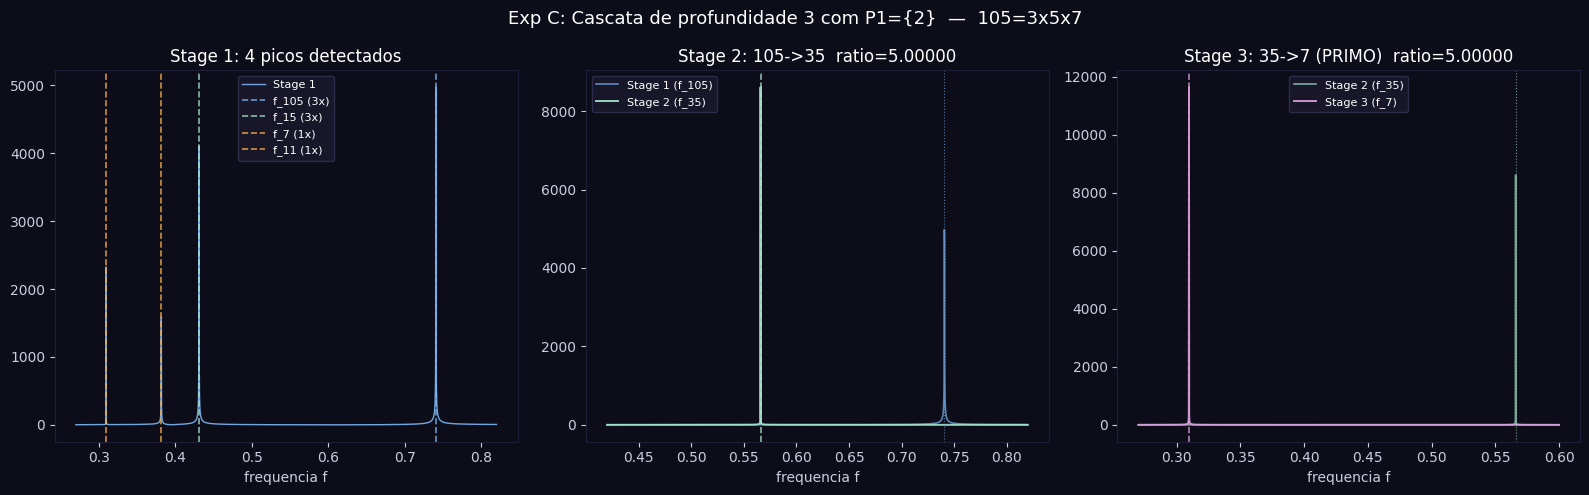

Figura salva: cascata_stage3_depth3.png


In [7]:
# Visualizacao Stage 1 do Exp C
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.patch.set_facecolor(BG)
fig.suptitle('Exp C: Cascata de profundidade 3 com P1={2}  —  105=3x5x7',
             color='white', fontsize=13)

# Espectro Stage 1
ax = axes[0]; ax.set_facecolor(BG)
f_lo, f_hi = 0.27, 0.82
mask = (freqs > f_lo) & (freqs < f_hi)
ax.plot(freqs[mask], F1C[mask], color=C_S1, lw=1.0, alpha=0.9, label='Stage 1')
for cf,cor,lbl in [(105,C_S1,'105 (3x)'),(15,C_S2,'15 (3x)'),
                   (7,C_CTRL,'7 (1x)'),(11,C_CTRL,'11 (1x)')]:
    ax.axvline(math.log(cf)/(2*math.pi), color=cor, lw=1.2, ls='--', alpha=0.8, label=f'f_{lbl}')
ax.set_title('Stage 1: 4 picos detectados', color='white')
ax.set_xlabel('frequencia f', color=C_TEXT)
ax.legend(facecolor='#1A1A2E', edgecolor='#333355', labelcolor='white', fontsize=8)
ax.tick_params(colors=C_TEXT)
for s in ax.spines.values(): s.set_edgecolor(C_GRID)

# Stage 2 vs Stage 1 para Grupo 1
ax2 = axes[1]; ax2.set_facecolor(BG)
F1g1 = espectro(sinal_de(GRUPO1, lambda m: log_res(m, P1_C)))
f_lo2, f_hi2 = 0.42, 0.82
mask2 = (freqs > f_lo2) & (freqs < f_hi2)
ax2.plot(freqs[mask2], F1g1[mask2], color=C_S1, lw=1.2, alpha=0.7, label='Stage 1 (f_105)')
ax2.plot(freqs[mask2], F2a[mask2],  color=C_S2, lw=1.4, alpha=0.9, label='Stage 2 (f_35)')
ax2.axvline(math.log(105)/(2*math.pi), color=C_S1, lw=0.8, ls=':', alpha=0.6)
ax2.axvline(math.log(35)/(2*math.pi),  color=C_S2, lw=1.2, ls='--', alpha=0.8)
ax2.set_title(f'Stage 2: 105->35  ratio={r2a:.5f}', color='white')
ax2.set_xlabel('frequencia f', color=C_TEXT)
ax2.legend(facecolor='#1A1A2E', edgecolor='#333355', labelcolor='white', fontsize=8)
ax2.tick_params(colors=C_TEXT)
for s in ax2.spines.values(): s.set_edgecolor(C_GRID)

# Stage 3 vs Stage 2
ax3 = axes[2]; ax3.set_facecolor(BG)
f_lo3, f_hi3 = 0.27, 0.60
mask3 = (freqs > f_lo3) & (freqs < f_hi3)
ax3.plot(freqs[mask3], F2a[mask3], color=C_S2, lw=1.2, alpha=0.7, label='Stage 2 (f_35)')
ax3.plot(freqs[mask3], F3[mask3],  color=C_S3, lw=1.4, alpha=0.9, label='Stage 3 (f_7)')
ax3.axvline(math.log(35)/(2*math.pi), color=C_S2, lw=0.8, ls=':', alpha=0.6)
ax3.axvline(math.log(7)/(2*math.pi),  color=C_S3, lw=1.2, ls='--', alpha=0.8)
ax3.set_title(f'Stage 3: 35->7 (PRIMO)  ratio={r3:.5f}', color='white')
ax3.set_xlabel('frequencia f', color=C_TEXT)
ax3.legend(facecolor='#1A1A2E', edgecolor='#333355', labelcolor='white', fontsize=8)
ax3.tick_params(colors=C_TEXT)
for s in ax3.spines.values(): s.set_edgecolor(C_GRID)

plt.tight_layout()
plt.savefig('cascata_stage3_depth3.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Figura salva: cascata_stage3_depth3.png')


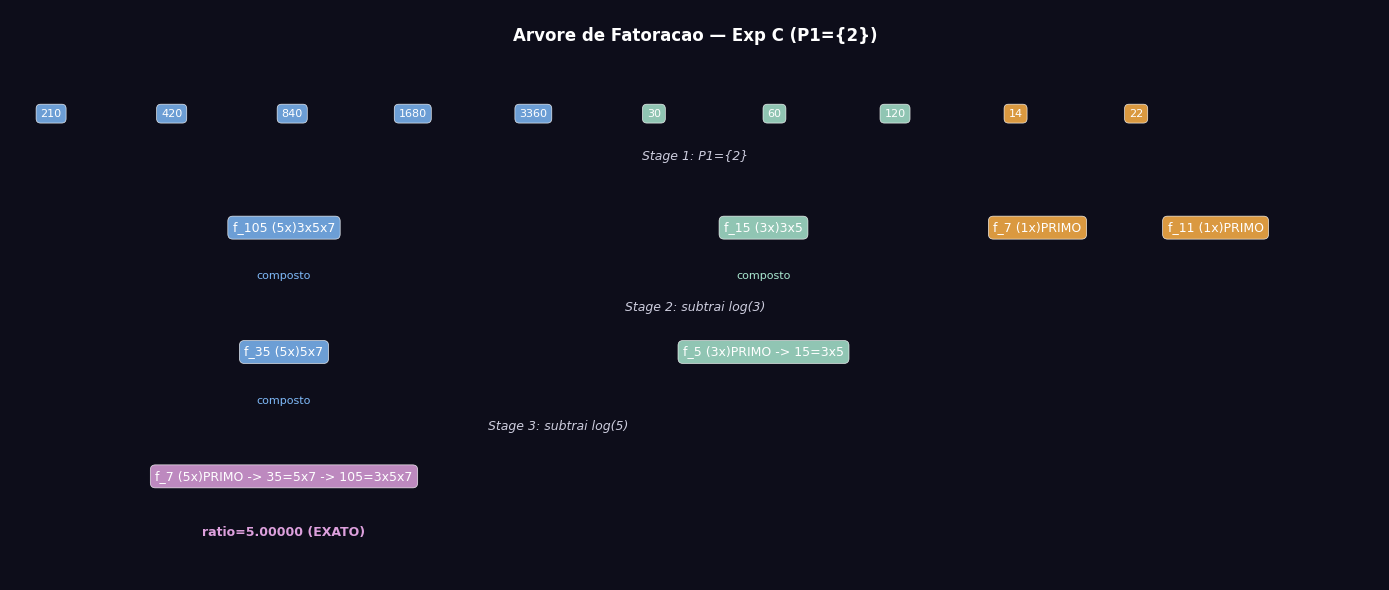

Figura salva: cascata_arvore_depth3.png


In [9]:
# Arvore de fatorizacao Exp C
fig, ax = plt.subplots(figsize=(14, 6))
fig.patch.set_facecolor(BG); ax.set_facecolor(BG)
ax.set_xlim(0,10); ax.set_ylim(0,5.5); ax.axis('off')

def cx(ax,x,y,txt,cor,fs=9):
    ax.text(x,y,txt,ha='center',va='center',fontsize=fs,color='white',
            bbox=dict(boxstyle='round,pad=0.4',facecolor=cor,alpha=0.85,
                      edgecolor='white',lw=0.5))
def arr(ax,x1,y1,x2,y2):
    ax.annotate('',xy=(x2,y2),xytext=(x1,y1),
                arrowprops=dict(arrowstyle='->',color=C_TEXT,lw=1.2))

ax.text(5,5.2,'Arvore de Fatoracao — Exp C (P1={2})',ha='center',
        fontsize=12,color='white',fontweight='bold')

# Nivel 0: candidatos
for i,m in enumerate(TODOS_C):
    cor=C_S1 if m in GRUPO1 else (C_S2 if m in GRUPO2 else C_CTRL)
    cx(ax,0.3+i*0.88,4.5,str(m),cor,fs=8)

ax.text(5,4.05,'Stage 1: P1={2}',ha='center',fontsize=9,color=C_TEXT,style='italic')

# Nivel 1: Stage 1
cx(ax,2.0,3.4,'f_105 (5x)3x5x7',C_S1)
cx(ax,5.5,3.4,'f_15 (3x)3x5',C_S2)
cx(ax,7.5,3.4,'f_7 (1x)PRIMO',C_CTRL)
cx(ax,8.8,3.4,'f_11 (1x)PRIMO',C_CTRL)

ax.text(2.0,2.9,'composto',ha='center',fontsize=8,color=C_S1)
ax.text(5.5,2.9,'composto',ha='center',fontsize=8,color=C_S2)
ax.text(5,2.6,'Stage 2: subtrai log(3)',ha='center',fontsize=9,color=C_TEXT,style='italic')

# Nivel 2: Stage 2
cx(ax,2.0,2.2,'f_35 (5x)5x7',C_S1)
cx(ax,5.5,2.2,'f_5 (3x)PRIMO -> 15=3x5',C_S2)

ax.text(2.0,1.7,'composto',ha='center',fontsize=8,color=C_S1)
ax.text(4.0,1.45,'Stage 3: subtrai log(5)',ha='center',fontsize=9,color=C_TEXT,style='italic')

# Nivel 3: Stage 3
cx(ax,2.0,1.0,'f_7 (5x)PRIMO -> 35=5x7 -> 105=3x5x7',C_S3)

ax.text(2.0,0.42,'ratio=5.00000 (EXATO)',ha='center',fontsize=9,
        color=C_S3,fontweight='bold')

plt.tight_layout()
plt.savefig('cascata_arvore_depth3.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Figura salva: cascata_arvore_depth3.png')


In [10]:
import zipfile, os

arquivos = ['escala_exp_a.png','cascata_stage3_depth3.png','cascata_arvore_depth3.png']
with zipfile.ZipFile('escala_stage3_resultados.zip','w') as zf:
    for arq in arquivos:
        if os.path.exists(arq): zf.write(arq)

print('Pacote: escala_stage3_resultados.zip')
for arq in arquivos:
    print(f'  [{"OK" if os.path.exists(arq) else "FALTANDO"}] {arq}')


Pacote: escala_stage3_resultados.zip
  [OK] escala_exp_a.png
  [OK] cascata_stage3_depth3.png
  [OK] cascata_arvore_depth3.png
